# Objective 2 - Linear Regression

Sairaj Jaspalsinh Rajput - S397925

Kiran Subedi - S400572

# Part 1 – Data preparation (Sairaj)

In [1]:
import random
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

PERMA_SEED = 42
random.seed(PERMA_SEED)
np.random.seed(PERMA_SEED)

conn = sqlite3.connect("../db/fifa2026.db")

matches = pd.read_sql("SELECT * FROM matches", conn)
teams = pd.read_sql("SELECT * FROM teams", conn)
squads = pd.read_sql("SELECT * FROM squads_and_players", conn)
venues = pd.read_sql("SELECT * FROM venues", conn)
stages = pd.read_sql("SELECT * FROM tournament_stages", conn)

print(matches.shape, teams.shape, squads.shape, venues.shape, stages.shape)


(104, 17) (48, 8) (1248, 10) (16, 8) (7, 3)


In [2]:
# age of each player on the opening day
squads["age"] = (pd.to_datetime("2026-06-11") - pd.to_datetime(squads["date_of_birth"])).dt.days / 365.25

# one row per team
team_info = squads.groupby("team_id").agg(
    squad_value=("market_value_eur", "sum"),
    avg_age=("age", "mean"),
    total_caps=("caps", "sum"),
    avg_height=("height_cm", "mean"),
).reset_index()

# goals scored by each team's forwards
fwd_goals = squads[squads["position"] == "FWD"].groupby("team_id")["goals"].sum().reset_index(name="fwd_goals")

team_info = team_info.merge(fwd_goals, on="team_id")
team_info = team_info.merge(teams[["team_id", "team_name", "fifa_code", "elo_rating"]], on="team_id")

print(team_info.shape)
team_info.sort_values("squad_value", ascending=False).head()

(48, 9)


,team_id,squad_value,avg_age,total_caps,avg_height,fwd_goals,team_name,fifa_code,elo_rating
28,29,2134173029,26.747433,758,181.730769,78,Spain,ESP,2120
32,33,1546204469,27.001000,816,184.923077,83,France,FRA,2100
44,45,1321818896,27.273206,853,184.615385,126,England,ENG,2050
40,41,1145908765,28.035276,1176,181.500000,188,Portugal,POR,2010
36,37,1025039444,29.118201,1267,179.576923,179,Argentina,ARG,2150


In [3]:
# add stages (group/knockout) and venue details to each match
matches = matches.merge(stages[["stage_id", "is_knockout"]], on="stage_id")
matches = matches.merge(venues[["venue_id", "country", "elevation_meters"]], on="venue_id")
matches["kickoff"] = pd.to_datetime(matches["date"] + " " + matches["kickoff_time_utc"])

# each match has two teams, so making one row for each team
home = pd.DataFrame({
    "match_id": matches["match_id"], "kickoff": matches["kickoff"],
    "team_id": matches["home_team_id"], "opp_id": matches["away_team_id"],
    "goals_for": matches["home_score"], "goals_against": matches["away_score"],
    "xg_for": matches["home_xg"], "xg_against": matches["away_xg"],
    "is_home": 1, "is_knockout": matches["is_knockout"],
    "venue_country": matches["country"], "elevation": matches["elevation_meters"],
})
away = pd.DataFrame({
    "match_id": matches["match_id"], "kickoff": matches["kickoff"],
    "team_id": matches["away_team_id"], "opp_id": matches["home_team_id"],
    "goals_for": matches["away_score"], "goals_against": matches["home_score"],
    "xg_for": matches["away_xg"], "xg_against": matches["home_xg"],
    "is_home": 0, "is_knockout": matches["is_knockout"],
    "venue_country": matches["country"], "elevation": matches["elevation_meters"],
})

team_matches = pd.concat([home,away]).sort_values(["team_id", "kickoff"]).reset_index(drop=True)
print(team_matches.shape)


(208, 12)


In [4]:
by_team = team_matches.groupby("team_id")
games_before = by_team.cumcount()

# avarage xG from earlier matches only (this match is subtracte)
team_matches["prev_xg_for"] = (by_team["xg_for"].cumsum() - team_matches["xg_for"]) / games_before
team_matches["prev_xg_against"] = (by_team["xg_against"].cumsum() - team_matches["xg_against"]) / games_before
team_matches["rest_days"] = by_team["kickoff"].diff().dt.days

# first match of each team: no history yet
team_matches["prev_xg_for"] = team_matches["prev_xg_for"].fillna(1.3)
team_matches["prev_xg_against"] = team_matches["prev_xg_against"].fillna(1.3)
team_matches["rest_days"] = team_matches["rest_days"].fillna(7)

# add squad stats, and mark host nations playing in their own country
team_matches = team_matches.merge(team_info, on="team_id")
team_matches["is_host"] = (team_matches["fifa_code"] == team_matches["venue_country"]).astype(int)

team_matches[["team_name", "match_id", "xg_for", "prev_xg_for", "rest_days", "is_host"]].head(6)

,team_name,match_id,xg_for,prev_xg_for,rest_days,is_host
0,Mexico,1,1.84,1.300000,7.0,1
1,Mexico,25,1.62,1.840000,6.0,1
2,Mexico,49,1.27,1.730000,6.0,1
3,Mexico,79,1.02,1.576667,6.0,1
4,Mexico,92,1.88,1.437500,4.0,1
5,South Africa,1,0.52,1.300000,7.0,0


## Part 2 – LR 2.1: Predicting goal difference (Kiran)
One row per match (104 rows). Target = home goals − away goals.
Each feature is **home team value − away team value**, except `is_knockout`.

| Feature | Meaning |
|---|---|
| elo_diff | Difference in pre-tournament Elo rating |
| value_diff | log(home squad value) − log(away squad value) |
| age_diff | Difference in average squad age |
| fwd_goals_diff | Difference in forwards' international goals |
| prev_xg_diff | Difference in xG form (xG for − against) from earlier matches |
| rest_diff | Difference in rest days |
| host_diff | Host nation playing at home |
| is_knockout | 1 if knockout stage |

In [5]:
# Separate home and away team rows so they can be compared by match.
h = team_matches[team_matches["is_home"] == 1].set_index("match_id").sort_index()
a = team_matches[team_matches["is_home"] == 0].set_index("match_id").sort_index()

# Calculate home-minus-away differences for each feature and the match result.
lr1 = pd.DataFrame({
    "elo_diff": h["elo_rating"] - a["elo_rating"],
    "value_diff": np.log(h["squad_value"]) - np.log(a["squad_value"]),
    "age_diff": h["avg_age"] - a["avg_age"],
    "fwd_goals_diff": h["fwd_goals"] - a["fwd_goals"],
    "prev_xg_diff": (h["prev_xg_for"] - h["prev_xg_against"]) - (a["prev_xg_for"] - a["prev_xg_against"]),
    "rest_diff": h["rest_days"] - a["rest_days"],
    "host_diff": h["is_host"] - a["is_host"],
    "is_knockout": h["is_knockout"],
    "goal_difference": h["goals_for"] - h["goals_against"],
}).reset_index()

# List the input features that will be used to predict goal difference.
features1 = ["elo_diff", "value_diff", "age_diff", "fwd_goals_diff",
             "prev_xg_diff", "rest_diff", "host_diff", "is_knockout"]

# Check the dataset size and count any missing values.
print(lr1.shape)
print("Missing values:", lr1.isna().sum().sum())
lr1.head()

(104, 10)
Missing values: 0


,match_id,elo_diff,value_diff,age_diff,fwd_goals_diff,prev_xg_diff,rest_diff,host_diff,is_knockout,goal_difference
0,1,190,2.155865,1.092297,42,0.0,0.0,1,0,2
1,2,60,-0.297033,0.444901,22,0.0,0.0,0,0,1
2,3,150,0.332921,0.516190,2,0.0,0.0,1,0,0
3,4,125,1.046996,-2.097615,62,0.0,0.0,1,0,3
4,5,-260,-1.079986,1.200653,100,0.0,0.0,0,0,0


### Descriptive statistics

In [6]:
# To Summarize the feature values and goal differences.
lr1[features1 + ["goal_difference"]].describe().round(2)

,elo_diff,value_diff,age_diff,fwd_goals_diff,prev_xg_diff,rest_diff,host_diff,is_knockout,goal_difference
count,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00
mean,57.02,0.34,0.03,5.62,0.24,0.02,0.07,0.31,0.48
std,236.67,1.38,1.47,55.39,1.38,0.74,0.35,0.46,2.02
min,-540.00,-2.82,-3.45,-148.00,-3.90,-1.00,-1.00,0.00,-4.00
25%,-112.50,-0.79,-0.96,-30.00,-0.26,0.00,0.00,0.00,-1.00
50%,60.00,0.54,-0.02,4.00,0.00,0.00,0.00,0.00,0.00
75%,226.25,1.22,1.11,39.25,1.04,0.00,0.00,1.00,2.00
max,510.00,3.21,3.15,144.00,4.23,3.00,1.00,1.00,6.00


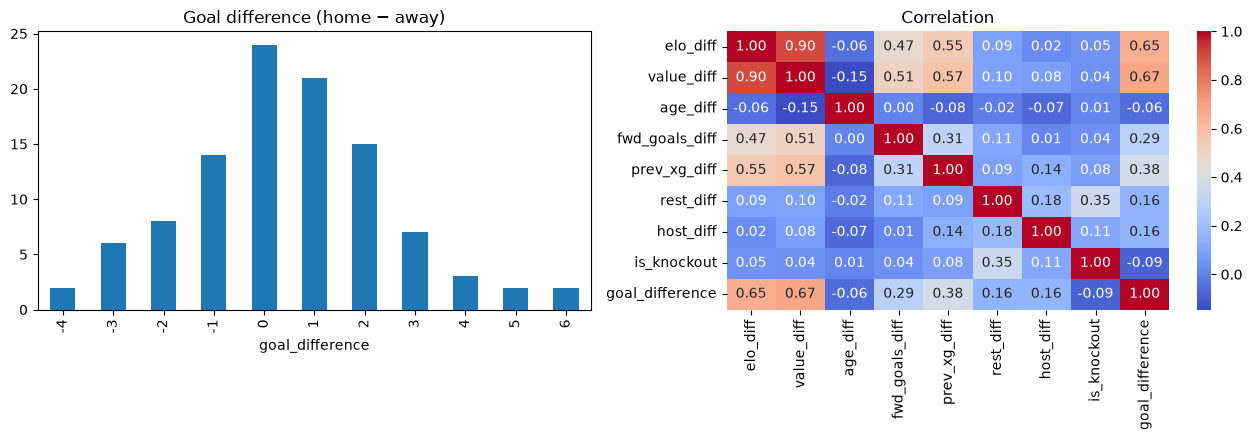

In [7]:
# To compare the goal difference counts with correlations between variables.
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lr1["goal_difference"].value_counts().sort_index().plot(kind="bar", ax=ax[0])
ax[0].set_title("Goal difference (home − away)")
sns.heatmap(lr1[features1 + ["goal_difference"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation")
plt.tight_layout()
plt.show()

### Train and evaluate

In [8]:
# Here I Separated the input features from the goal-difference target.
X1 = lr1[features1]
y1 = lr1["goal_difference"]

# To keep some matches aside to test how well the model predicts new data.
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=PERMA_SEED)

# Training the linear regression model and predict the test-set results.
model1 = LinearRegression()
model1.fit(X1_train, y1_train)
y1_pred = model1.predict(X1_test)

# Show the estimated effect of each feature.
pd.Series(model1.coef_, index=features1).round(4)

elo_diff          0.0014
value_diff        0.9390
age_diff          0.0030
fwd_goals_diff   -0.0031
prev_xg_diff     -0.0650
rest_diff         0.2046
host_diff         0.7360
is_knockout      -0.8362
dtype: float64

In [9]:
# To Calculate common error scores and R-squared to measure prediction quality.
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse / (y_true.max() - y_true.min())
    r2 = r2_score(y_true, y_pred)
    print(f"MAE: {mae:.3f}  MSE: {mse:.3f}  RMSE: {rmse:.3f}  NRMSE: {nrmse:.3f}  R2: {r2:.3f}")

# Here I used the training-set average as a simple baseline for comparison.
baseline1 = np.full(len(y1_test), y1_train.mean())

print("Baseline:")
evaluate(y1_test, baseline1)
print("Linear regression:")
evaluate(y1_test, y1_pred)

Baseline:
MAE: 1.782  MSE: 5.147  RMSE: 2.269  NRMSE: 0.252  R2: -0.017
Linear regression:
MAE: 1.537  MSE: 3.574  RMSE: 1.890  NRMSE: 0.210  R2: 0.294


In [10]:
# Fitted an OLS model to get p-values and adjusted R-squared for our report.
ols1 = sm.OLS(y1_train, sm.add_constant(X1_train)).fit()
print(ols1.summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.573
Model:                            OLS   Adj. R-squared:                  0.527
Method:                 Least Squares   F-statistic:                     12.44
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           4.01e-11
Time:                        21:34:48   Log-Likelihood:                -137.66
No. Observations:                  83   AIC:                             293.3
Df Residuals:                      74   BIC:                             315.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.3143      0.183      1.

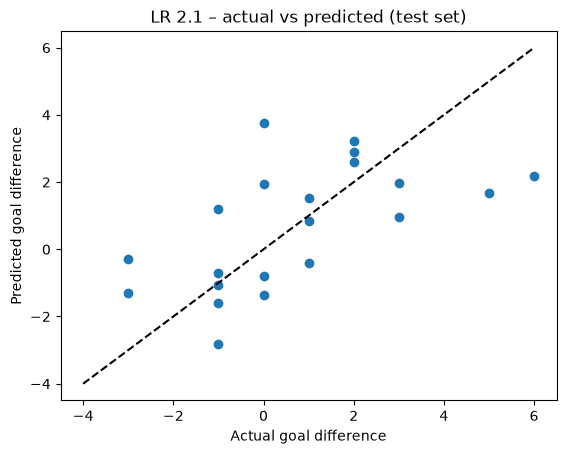

In [11]:
# Compared actual and predicted goal differences for the test matches.
plt.scatter(y1_test, y1_pred)

# Here the dashed line shows where predictions would exactly match actual values.
plt.plot([-4, 6], [-4, 6], "k--")
plt.xlabel("Actual goal difference")
plt.ylabel("Predicted goal difference")
plt.title("LR 2.1 – actual vs predicted (test set)")
plt.show()

## Part 3 – LR 2.2: Predicting goals scored by a team (Sairaj)
One row per team per match (208 rows). Target = goals scored by that team.

| Feature | Meaning | Related to LR 2.1? |
|---|---|---|
| elo_rating | Team's pre-tournament Elo | yes (Elo) |
| opp_elo_rating | Opponent's pre-tournament Elo | yes (Elo) |
| prev_xg_for | Team's average xG in earlier matches | yes (xG form) |
| fwd_goals | Team's forwards' international goals | yes (forwards' goals) |
| avg_height | Team's average height | no |
| opp_avg_height | Opponent's average height | no |
| total_caps | Team's total international caps (experience) | no |
| elevation_km | Stadium altitude in km | no |

Only 4 features are related to LR 2.1, which is the maximum allowed.

In [12]:
# added the opponent's Elo score and height to each of the row
opp = team_matches[["match_id", "team_id", "elo_rating", "avg_height"]].rename(
    columns={"team_id": "opp_id", "elo_rating": "opp_elo_rating", "avg_height": "opp_avg_height"})

lr2 = team_matches.merge(opp, on=["match_id", "opp_id"])
lr2["elevation_km"] = lr2["elevation"] / 1000

features2 = ["elo_rating", "opp_elo_rating", "prev_xg_for", "fwd_goals",
             "avg_height", "opp_avg_height", "total_caps", "elevation_km"]

lr2 = lr2[["match_id", "team_id", "opp_id"] + features2 + ["goals_for"]].sort_values(["match_id", "team_id"])

print(lr2.shape)
print("Missing values:", lr2.isna().sum().sum())
lr2.head()

(208, 12)
Missing values: 0


,match_id,team_id,opp_id,elo_rating,opp_elo_rating,prev_xg_for,fwd_goals,avg_height,opp_avg_height,total_caps,elevation_km,goals_for
0,1,1,2,1810,1620,1.3,75,179.500000,178.846154,1237,2.200,2
5,1,2,1,1620,1810,1.3,33,178.846154,179.500000,538,2.200,0
9,2,3,4,1800,1740,1.3,75,181.923077,185.730769,974,1.566,2
12,2,4,3,1740,1800,1.3,53,185.730769,181.923077,738,1.566,1
15,3,5,6,1795,1645,1.3,87,182.307692,187.076923,973,0.076,1
